# Customer Churn Predition

Step1. Import

In [1]:
# Standard imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Metrics & utilities
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import joblib
import warnings
warnings.filterwarnings("ignore")

# Display setting
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
pd.set_option('display.max_columns', 200)

# Step2.Load the data 

In [2]:
# Load dataset
df = pd.read_csv("Churn_Modelling.csv")

print("Shape:", df.shape)
df.head()

Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# Step 3.Initial inspection

In [3]:
# Info & Summary
display(df.info())
display(df.describe(include='all').T)

# Missing values
print("\nmissing value per column:")
print(df.isnull().sum())

# Target distribution
print("n\Churn value counts:")
print(df['Exited'].value_counts(normalize=False))
print("\nChurn proportion:")
print(df['Exited'].value_counts(normalize=True))

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0



missing value per column:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
n\Churn value counts:
Exited
0    7963
1    2037
Name: count, dtype: int64

Churn proportion:
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


In [4]:
print(df.columns.tolist())

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


# step 4. Exploratory Data Analysis (Visualization)

We'll look at the distribution of numeric features, their relationships with churn, and categorical features.

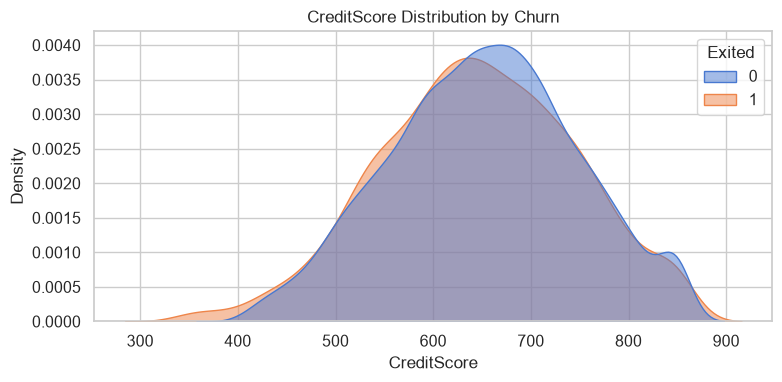

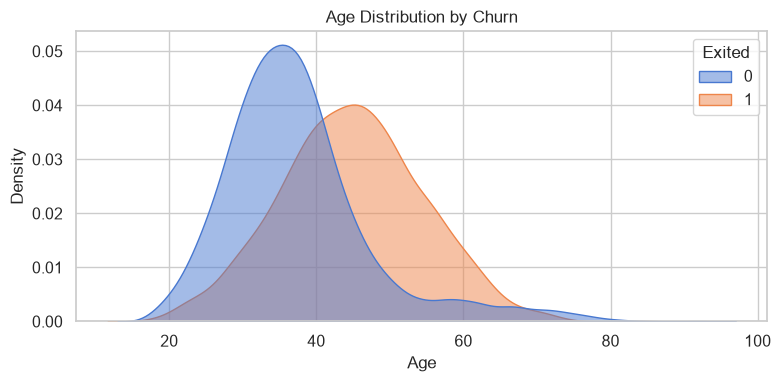

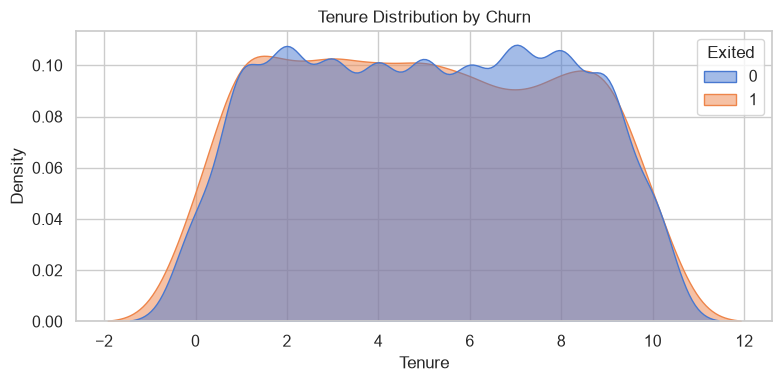

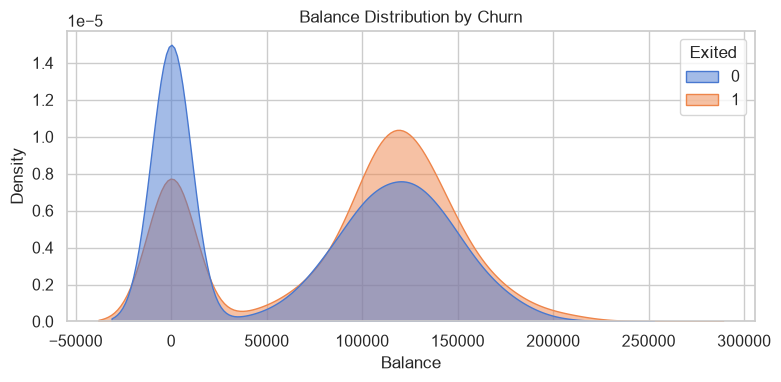

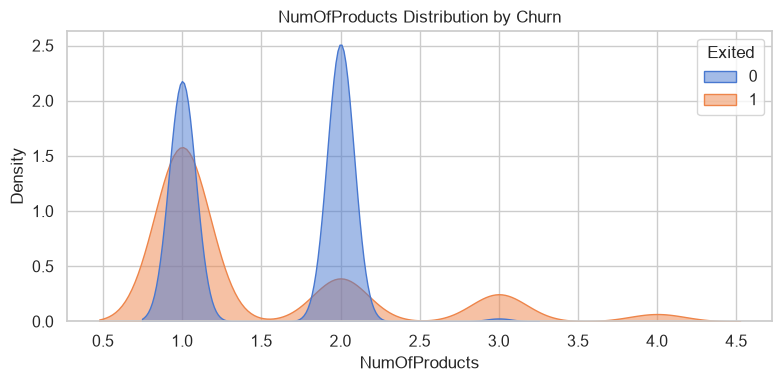

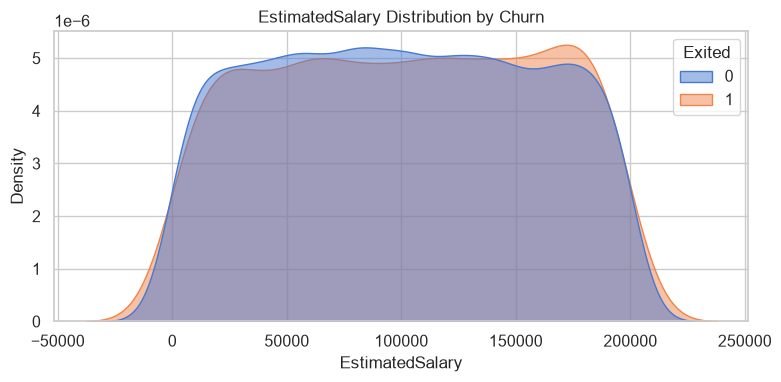

In [5]:
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

# --- Distribution plots
for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.kdeplot(data=df, x=col, hue='Exited', fill=True, common_norm=False, alpha=0.5)
    plt.title(f"{col} Distribution by Churn")
    plt.tight_layout()
    plt.show()

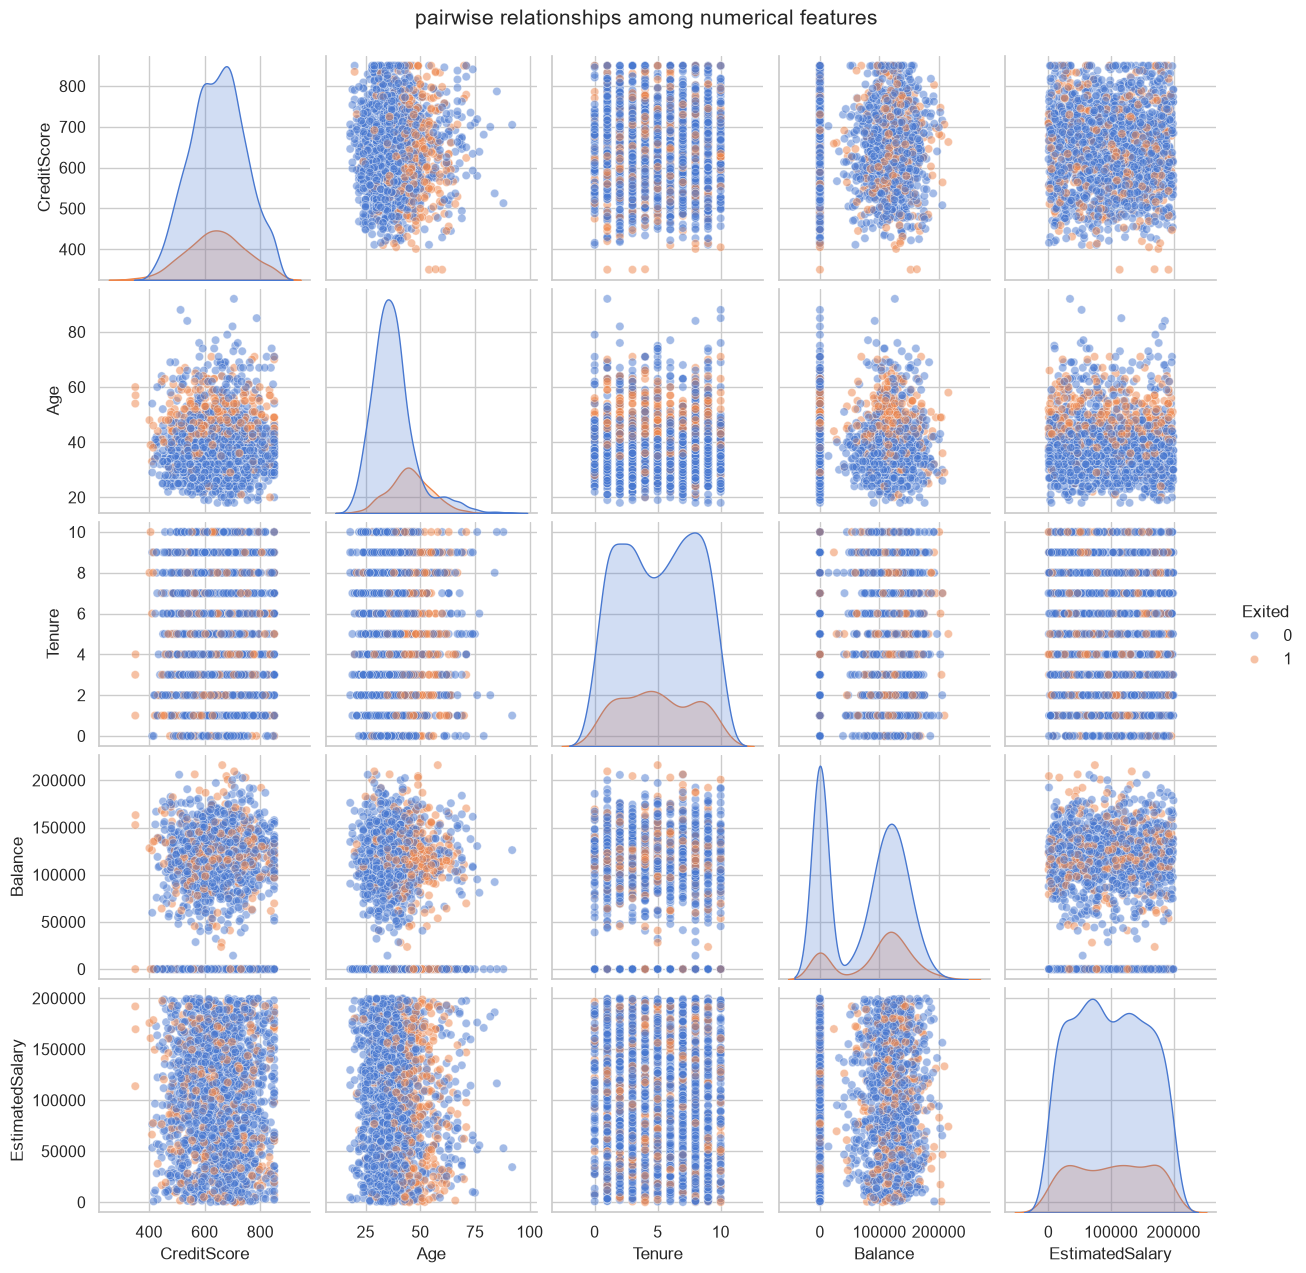

In [6]:
#  ---pairplot(sampled for speed)

sns.pairplot(df.sample(frac=0.2, random_state=42),
             vars=['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary'],
             hue='Exited', diag_kind='kde', plot_kws={'alpha': 0.5})
plt.suptitle('pairwise relationships among numerical features', y=1.02)
plt.show()

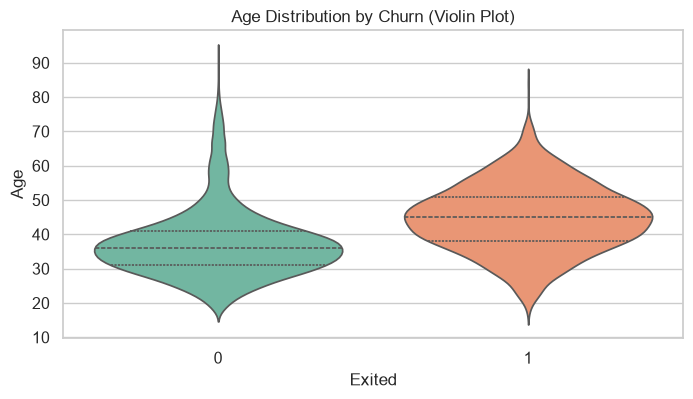

In [7]:
# --- Violin plot for Age 
plt.figure(figsize=(8, 4))
sns.violinplot(data=df, x='Exited', y='Age', inner='quartile', palette='Set2')
plt.title('Age Distribution by Churn (Violin Plot)')
plt.show()

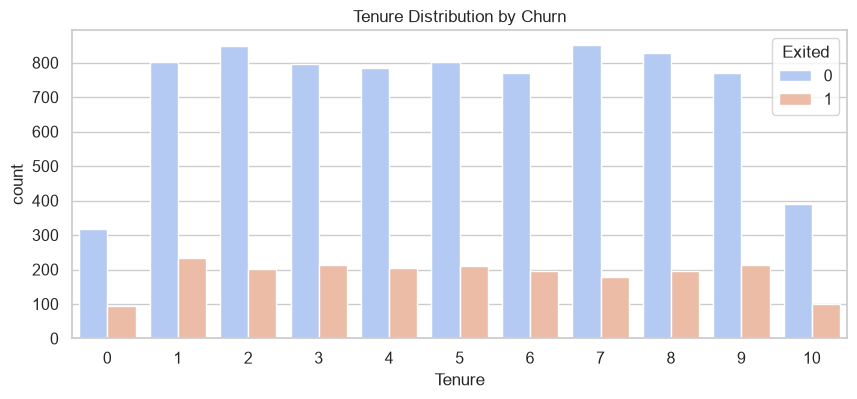

In [8]:
# --- Tenure distribution
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='Tenure', hue='Exited', palette='coolwarm')
plt.title('Tenure Distribution by Churn')
plt.show()

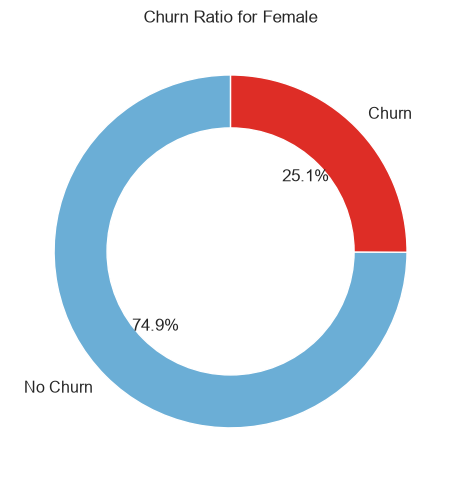

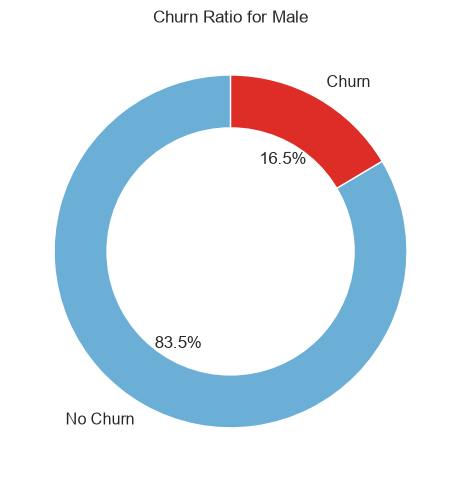

In [9]:
# --- Gender vs Churn Donut chart
gender_counts = df.groupby(['Gender', 'Exited']).size().unstack().fillna(0)
for gender in gender_counts.index:
    plt.figure(figsize=(5, 5))
    plt.pie(gender_counts.loc[gender], labels=['No Churn', 'Churn'],
            autopct='%1.1f%%', startangle=90, colors=['#6baed6', '#de2d26'])
    center = plt.Circle((0, 0), 0.70, fc='white')
    fig = plt.gcf()
    fig.gca().add_artist(center)
    plt.title(f'Churn Ratio for {gender}')
    plt.tight_layout()
    plt.show()

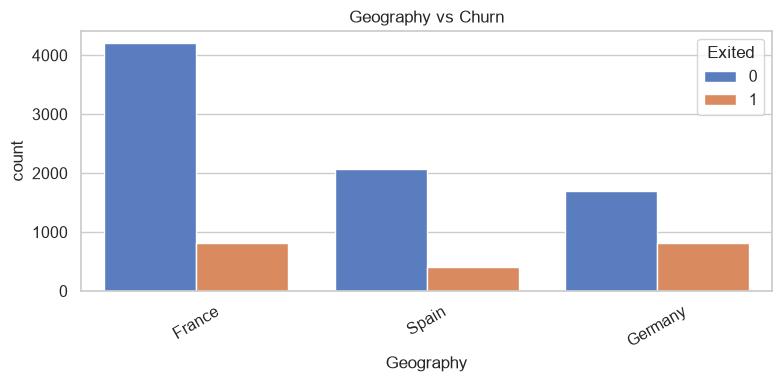

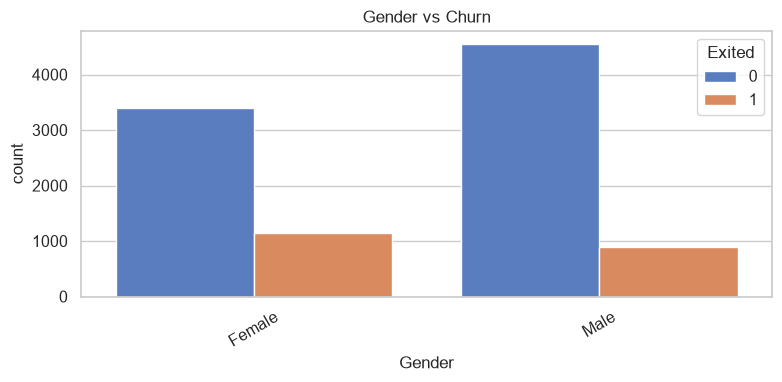

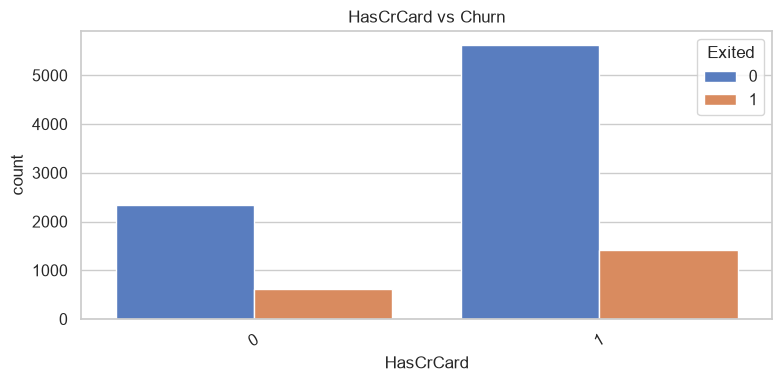

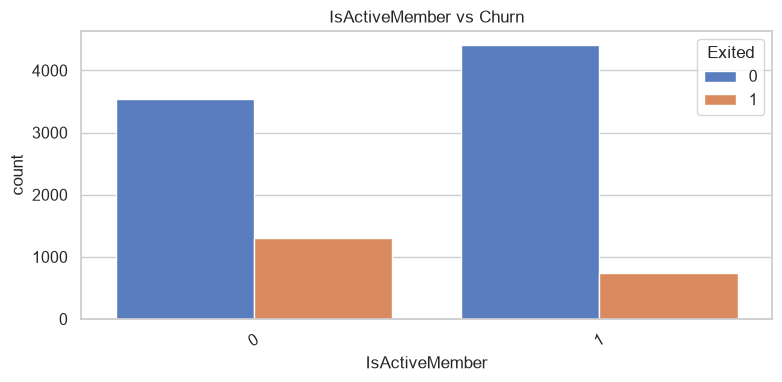

In [10]:
# --- Categorical features 
cat_cols = ['Geography', 'Gender', 'HasCrCard', 'IsActiveMember']
for c in cat_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=c, hue='Exited')
    plt.title(f'{c} vs Churn')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

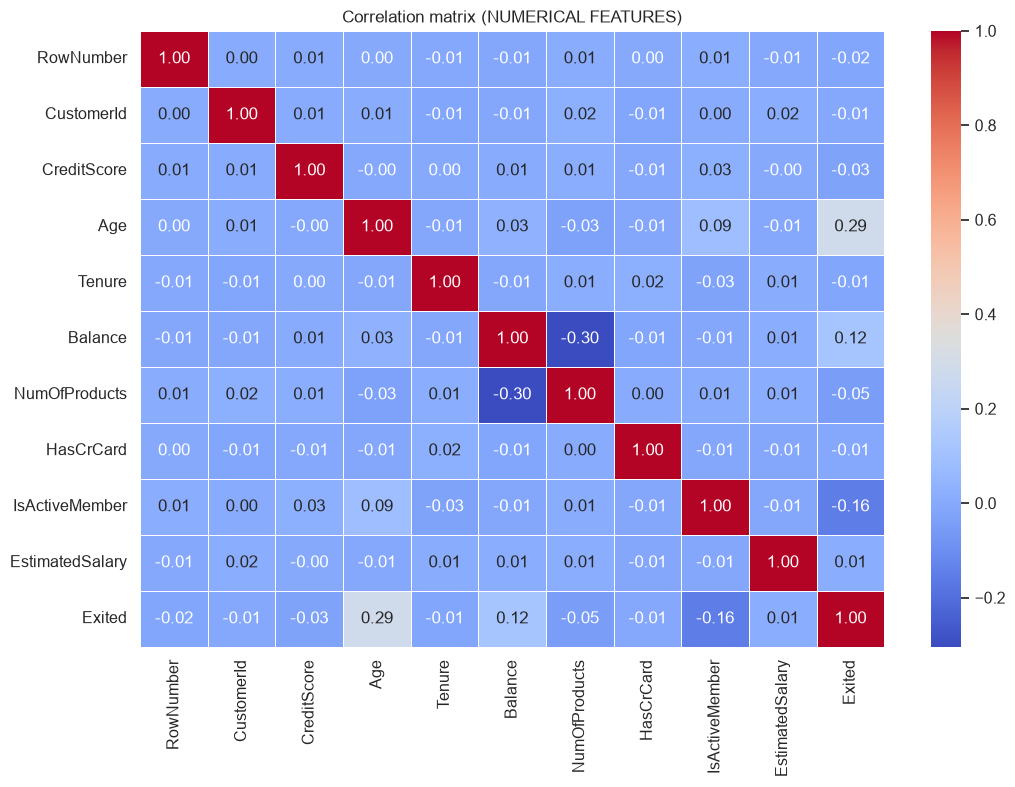

In [11]:
#---Heatmap visualization
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation matrix (NUMERICAL FEATURES)')
plt.show()

In [12]:
# --- Numerical Corellation heatmap
numerical_data = df[num_cols + ['Exited']] # use the numerical coulums from your feature-engineered dataframe
corr = numerical_data.corr()
corr.style.background_gradient(cmap='coolwarm')

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,Exited
CreditScore,1.000000,-0.003965,0.000842,0.006268,0.012238,-0.001384,-0.027094
Age,-0.003965,1.000000,-0.009997,0.028308,-0.030680,-0.007201,0.285323
Tenure,0.000842,-0.009997,1.000000,-0.012254,0.013444,0.007784,-0.014001
Balance,0.006268,0.028308,-0.012254,1.000000,-0.304180,0.012797,0.118533
NumOfProducts,0.012238,-0.030680,0.013444,-0.304180,1.000000,0.014204,-0.047820
EstimatedSalary,-0.001384,-0.007201,0.007784,0.012797,0.014204,1.000000,0.012097
Exited,-0.027094,0.285323,-0.014001,0.118533,-0.047820,0.012097,1.000000


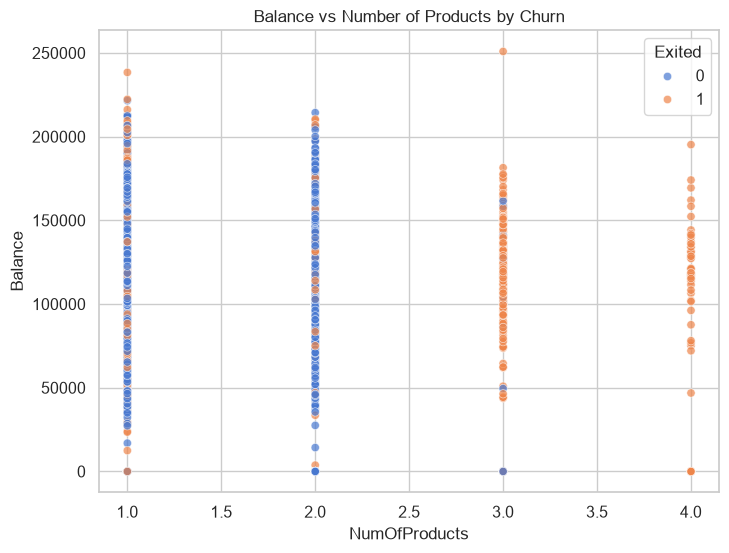

In [13]:
# --- Balance vs products scatter
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='NumOfProducts', y='Balance', hue='Exited', alpha=0.7)
plt.title('Balance vs Number of Products by Churn')
plt.show()

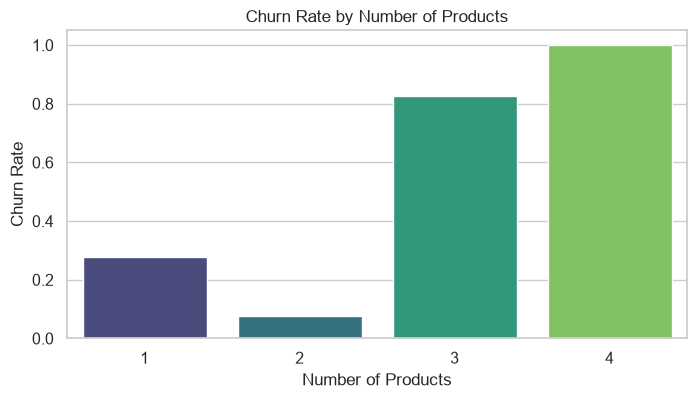

In [14]:
# --- Aggregate churn rate per number of products
churn_rate = df.groupby('NumOfProducts')['Exited'].mean().reset_index()

# plot churn rate
plt.figure(figsize=(8, 4))
sns.barplot(data=churn_rate, x='NumOfProducts', y='Exited', palette='viridis')
plt.xlabel('Number of Products')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Number of Products')
plt.show()

# Step 5. Feature Engineering

Create meaningful feature:e.g balance per product, age group,salary bracket and handel missing values.

In [15]:
# Check column names first
print(df.columns.tolist())

# Make a copy
df_fe = df.copy()

# Balance per product
df_fe['balance_per_product'] = (
    df_fe['Balance'] /
    df_fe['NumOfProducts'].replace(0, np.nan)
)
df_fe['balance_per_product'] = df_fe['balance_per_product'].fillna(0)

# Salary to balance ratio
df_fe['salary_balance_ratio'] = (
    df_fe['EstimatedSalary'] /
    df_fe['Balance'].replace(0, np.nan)
)

df_fe['salary_balance_ratio'] = (
    df_fe['salary_balance_ratio']
    .replace([np.inf, -np.inf], np.nan)
)

df_fe['salary_balance_ratio'] = (
    df_fe['salary_balance_ratio']
    .fillna(df_fe['salary_balance_ratio'].median())
)

# Age group
bins = [0, 25, 35, 45, 55, 65, 100]
labels = ['<25', '25-34', '35-44', '45-54', '55-64', '65+']

df_fe['age_group'] = pd.cut(
    df_fe['Age'],
    bins=bins,
    labels=labels
)

# Tenure bucket
df_fe['tenure_bucket'] = pd.cut(
    df_fe['Tenure'],
    bins=[-1, 0, 2, 5, 10, 100],
    labels=['0', '1-2', '3-5', '6-10', '10+']
)

# Flag high balance
df_fe['high_balance'] = (
    df_fe['Balance'] > df_fe['Balance'].quantile(0.75)
).astype(int)

# Quick checks
df_fe[
    [
        'balance_per_product',
        'salary_balance_ratio',
        'Age',
        'age_group',
        'Tenure',
        'tenure_bucket',
        'high_balance'
    ]
].head()

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


,balance_per_product,salary_balance_ratio,Age,age_group,Tenure,tenure_bucket,high_balance
0,0.000000,0.839258,42,35-44,2,1-2,0
1,83807.860000,1.342864,41,35-44,1,1-2,0
2,53220.266667,0.713585,42,35-44,8,6-10,1
3,0.000000,0.839258,39,35-44,1,1-2,0
4,125510.820000,0.630098,43,35-44,2,1-2,0


# Step 6.Preprocessing - encoding & scaling

We'll Build a preprocessing pipeline that encodes categorical features and scales numerical ones.

In [16]:
# Define target
target = 'Exited'

# Columns to exclude from features
drop_cols = ['customer_id', target]

# Numerical features
numerical_features = [
    'credit_score',
    'age',
    'tenure',
    'balance',
    'products_number',
    'estimated_salary',
    'balance_per_product',
    'salary_balance_ratio'
]

# Categorical features
categorical_features = [
    'country',
    'gender',
    'credit_card',
    'active_member',
    'age_group',
    'tenure_bucket',
    'high_balance'
]

# Check which columns actually exist
numerical_features = [
    col for col in numerical_features
    if col in df_fe.columns
]

categorical_features = [
    col for col in categorical_features
    if col in df_fe.columns
]

# Convert existing categorical columns to object
if categorical_features:
    df_fe[categorical_features] = df_fe[categorical_features].astype('object')

# Create feature list
features = [
    col for col in df_fe.columns
    if col not in drop_cols
]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Print results
print("Target:", target)
print("Features:", features)
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Target: Exited
Features: ['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'balance_per_product', 'salary_balance_ratio', 'age_group', 'tenure_bucket', 'high_balance']
Numerical features: ['balance_per_product', 'salary_balance_ratio']
Categorical features: ['age_group', 'tenure_bucket', 'high_balance']


 # Step 7. Train Test Split

In [17]:
x = df_fe[features]
y = df_fe[target]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Train shape:', x_train.shape)
print('Test shape:', x_test.shape)
print('Train Churn proportion:', y_train.mean())
print('Test Churn proportion:', y_test.mean())

Train shape: (8000, 18)
Test shape: (2000, 18)
Train Churn proportion: 0.20375
Test Churn proportion: 0.2035


# Step 8. Train Multiple models with a pipeline and compre using cross-validation

In [18]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=500),
    'RandomForest': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    'GradientBoosting': GradientBoostingClassifier(
        n_estimators=200,
        random_state=42
    ),
    'AdaBoost': AdaBoostClassifier(
        n_estimators=200,
        random_state=42
    ),
    'SVC': SVC(
        probability=True,
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    scores = cross_val_score(
        pipeline,
        x_train,
        y_train,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )

    results[name] = scores

    print(
        f"{name}: Mean ROC AUC = {scores.mean():.4f}, "
        f"Std = {scores.std():.4f}"
    )

LogisticRegression: Mean ROC AUC = 0.7436, Std = 0.0169
RandomForest: Mean ROC AUC = 0.7280, Std = 0.0207
GradientBoosting: Mean ROC AUC = 0.7584, Std = 0.0187
AdaBoost: Mean ROC AUC = 0.7549, Std = 0.0160
SVC: Mean ROC AUC = 0.6670, Std = 0.0232


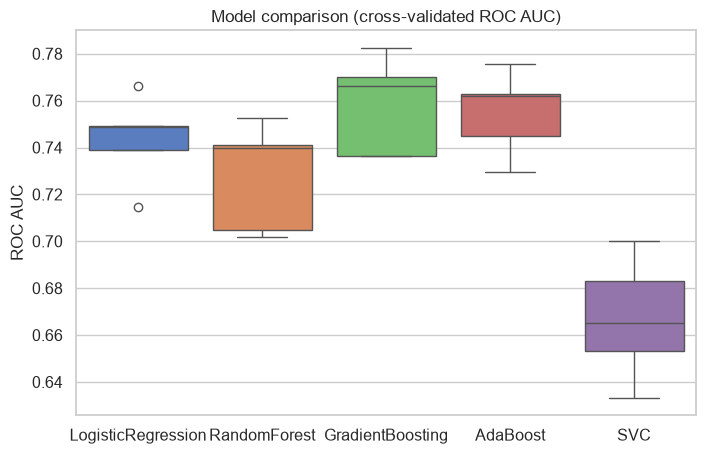

In [19]:
# Boxplot of CV AUC scores
plt.figure(figsize=(8,5))
sns.boxplot(data=[results[m] for m in list(results.keys())])
plt.xticks(range(len(results)), labels=list(results.keys()))
plt.ylabel('ROC AUC')
plt.title('Model comparison (cross-validated ROC AUC)')
plt.show()

# Step 9. FIt beat model on full train set and evaluate on test set

Select best model by mean CV AUC above and standard metrics on the test set

In [20]:
# choose best model (automatic pick by mean AUC)
best_name = max(results, key=lambda k: results[k].mean())
best_name, results[best_name].mean()

('GradientBoosting', np.float64(0.7583782781635543))

Test Accuracy: 0.8240
Test Precision: 0.6503
Test Recall: 0.2924
Test F1-score: 0.4034
Test ROC AUC: 0.7627

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.96      0.90      1593
           1       0.65      0.29      0.40       407

    accuracy                           0.82      2000
   macro avg       0.75      0.63      0.65      2000
weighted avg       0.80      0.82      0.80      2000



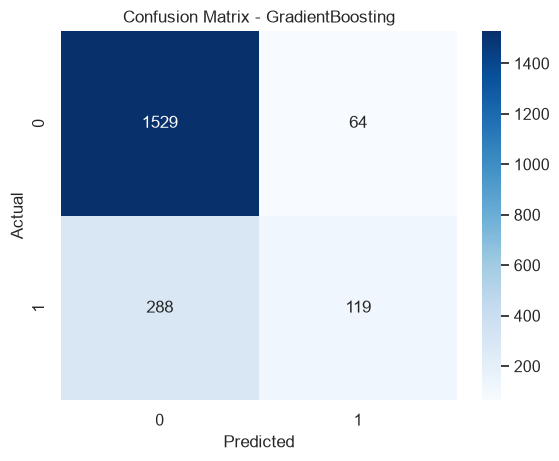

In [21]:
best_model = models[best_name]

best_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', best_model)
])

best_pipeline.fit(x_train, y_train)

# Predictions
y_pred = best_pipeline.predict(x_test)
y_proba = best_pipeline.predict_proba(x_test)[:, 1]

# Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc = roc_auc_score(y_test, y_proba)

print(f"Test Accuracy: {acc:.4f}")
print(f"Test Precision: {prec:.4f}")
print(f"Test Recall: {rec:.4f}")
print(f"Test F1-score: {f1:.4f}")
print(f"Test ROC AUC: {roc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_name}')
plt.show()

# Step 10. Feature importance(if applicable)

If the chosen model supports feature importance (RandomForest/GradienBoosting),show top features

age_group_45-54         0.308798
balance_per_product     0.224560
salary_balance_ratio    0.157243
age_group_55-64         0.130879
high_balance_1          0.058814
age_group_35-44         0.043429
high_balance_0          0.033808
age_group_25-34         0.019522
age_group_<25           0.005909
tenure_bucket_0         0.005515
tenure_bucket_6-10      0.004706
age_group_65+           0.003006
tenure_bucket_3-5       0.002267
tenure_bucket_1-2       0.001545
dtype: float64

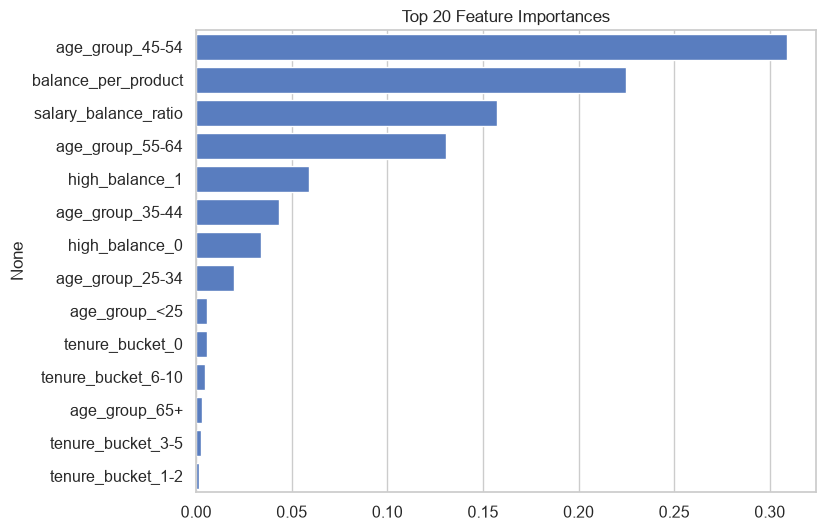

In [22]:
if hasattr(best_pipeline.named_steps['classifier'], 'feature_importances_'):
    num_feats = numerical_features
    cat_feats = list(best_pipeline.named_steps['preprocessor'].transformers_[1][1].named_steps['onehot'].get_feature_names_out(categorical_features))
    feature_names = num_feats + cat_feats
    importances = best_pipeline.named_steps['classifier'].feature_importances_
    fi = pd.Series(importances, index=feature_names).sort_values(ascending=False)[:20]
    display(fi)
    plt.figure(figsize=(8,6))
    sns.barplot(x=fi.values, y=fi.index)
    plt.title('Top 20 Feature Importances')
    plt.show()
else:
    print('Selected model does not provide feature importances attribute.')

# Step 11. Save tne best pipeline and preprocessing artifacts

In [23]:
joblib.dump(best_pipeline, 'best_Exited_pipeline.pkl')
print("saved best pipeline to 'best_Exited_pipeline.pkl'")

saved best pipeline to 'best_Exited_pipeline.pkl'


# Step 12 .Example: Predict Chrun for a new customer

In [24]:
# New customer sample
sample = {
    'customer_id': 373292028,
    'credit_score': 650,
    'country': 'France',
    'gender': 'Male',
    'age': 40,
    'tenure': 3,
    'balance': 50000.0,
    'products_number': 2,
    'credit_card': 1,
    'active_member': 1,
    'estimated_salary': 60000.0
}

sample_df = pd.DataFrame([sample])

# Apply same feature engineering
sample_df['balance_per_product'] = sample_df['balance'] / sample_df['products_number'].replace(0, np.nan)
sample_df['balance_per_product'].fillna(0, inplace=True)

sample_df['salary_balance_ratio'] = sample_df['estimated_salary'] / sample_df['balance'].replace(0, np.nan)
sample_df['salary_balance_ratio'] = (
    sample_df['salary_balance_ratio'].replace([np.inf, -np.inf], np.nan)
)
sample_df['salary_balance_ratio'].fillna(
    sample_df['salary_balance_ratio'].median(), inplace=True
)

bins = [0, 25, 35, 45, 55, 65, 100]
labels = ['<25', '25-34', '35-44', '45-54', '55-64', '65+']
sample_df['age_group'] = pd.cut(
    sample_df['age'],
    bins=bins,
    labels=labels
)

sample_df['tenure_bucket'] = pd.cut(
    sample_df['tenure'],
    bins=[-1, 0, 2, 5, 10],
    labels=['0', '1-2', '3-5', '6-10']
)

sample_df['high_balance'] = (
    sample_df['balance'] > 50000
).astype(int)

# Drop ID
sample_df = sample_df.drop(columns=['customer_id'])

# Predict
pred = best_pipeline.predict(sample_df)[0]
pred = best_pipeline.predict_proba(sample_df)[0,1]

print(f'Predicted chrun : {pred} , probability of chrun : {pred:.4f}')

Predicted chrun : 0.48566084625123224 , probability of chrun : 0.4857
